# El Quijote · Informe de generación de texto

Este informe estudia hasta qué punto una red neuronal puede aprender la escritura de una novela a partir de sus caracteres. Se comparan una RNN simple y una LSTM entrenadas con el texto de Don Quijote de la Mancha. La evaluación combina la predicción del siguiente carácter con la lectura de fragmentos generados.

**Uso en Colab.** Puedes leer las tablas y los gráficos ya guardados. Para repetir el experimento, selecciona *Entorno de ejecución → Ejecutar todas* y, si se solicita, sube el archivo `Don Quijote de la Mancha.txt`.

### Bibliotecas y mensajes de inicio

**Qué ocurre al ejecutar la primera celda.** Python carga las bibliotecas. TensorFlow y Keras construyen y entrenan las redes, NumPy organiza los datos en arreglos numéricos, pandas presenta las tablas y Matplotlib dibuja las curvas. La semilla numérica `42` ayuda a repetir el sorteo de muestras y la inicialización de los modelos. El equipo y las versiones instaladas pueden producir pequeñas diferencias.

**Cómo leer el aviso largo de Protobuf.** Protobuf es el formato que TensorFlow usa para representar datos estructurados. En la ejecución guardada, parte del código de TensorFlow se había generado con Protobuf **5.28.3**, y Python tenía instalada la versión **6.31.1** para ejecutarlo. La línea `UserWarning` avisa de esa diferencia y de una posible incompatibilidad en una versión futura. La ruta que empieza con `C:\Users\…` identifica el archivo de la biblioteca que emitió el aviso. Nombres como `tensor.proto` y `attr_value.proto` indican distintas definiciones que pasaron por la misma comprobación.

El entrenamiento continuó y dejó resultados guardados. En esta edición se conserva un ejemplo del aviso cuando apareció en la salida original. Al reejecutar en Colab, los avisos dependen de las versiones de ese entorno. Si una celda se detiene, la última línea del bloque `Traceback` identifica el error que sí interrumpió esa ejecución.

In [1]:
import ast
import io
import re
import zipfile
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display, Markdown

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
libro = Path("Don Quijote de la Mancha.txt")
archivo_zip = Path("dataset 3ra evaluacion.zip")
if not all(p.is_file() for p in [libro]):
    from google.colab import files
    print("Selecciona Don Quijote de la Mancha.txt.")
    files.upload()
for p in [libro]:
    if not p.is_file():
        raise FileNotFoundError(f"Falta {p.name}. Súbelo al directorio del cuaderno.")
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## Entregable 3.1 · Un modelo de caracteres para El Quijote
### 1. Lectura y preparación
Pasamos el libro a minúsculas y conservamos acentos, espacios, puntuación y saltos de línea. Cada entrada tiene los 30 caracteres anteriores y la etiqueta es el carácter inmediatamente posterior. Dividimos primero la novela en tres tramos consecutivos. Así evitamos que ventanas solapadas compartan caracteres entre entrenamiento, validación y prueba.

Tomamos ventanas al azar dentro de cada tramo. Usamos índices compactos y aplicamos *one-hot* por lote en el modelo. Esto representa exactamente qué carácter ocupa cada posición sin guardar una gran matriz tridimensional en memoria.

**Ejemplo de una ventana.** Imagina por un momento un contexto de cinco caracteres. Al leer `quijot`, la entrada sería `quijo` y la etiqueta correcta sería `t`. Al entrenar hacemos lo mismo con 30 caracteres. Una ventana puede terminar a mitad de palabra porque la unidad que se predice es una letra, un espacio, un signo o un salto de línea.

**Cómo leer el código y la primera tabla.** `X` contiene los contextos y `y` sus respuestas correctas. `Xv, yv` sirven para comparar configuraciones y `Xt, yt` para la prueba final. Reservamos el 80 % inicial de la novela para entrenamiento, el 10 % siguiente para validación y el último 10 % para prueba. *Ventanas posibles* cuenta todos los puntos de partida válidos. *Ventanas usadas* cuenta la muestra tomada de esos puntos. Se entrenó con 18 000 ventanas y se usaron 2 500 en cada evaluación.

**Del carácter al número.** Cada carácter conocido tiene un índice. El mapa inverso permite volver a mostrar letras al generar texto. El código reservado para un carácter desconocido permite leer caracteres que aparecen por primera vez fuera del tramo de entrenamiento. La representación *one-hot* coloca un 1 en la posición del carácter y ceros en las demás.

In [2]:
text = libro.read_text(encoding="utf-8-sig").lower()
c1, c2 = int(.8*len(text)), int(.9*len(text))
tramos = [text[:c1], text[c1:c2], text[c2:]]
chars = sorted(set(tramos[0]))
char_to_indices = {c:i for i,c in enumerate(chars)}
indices_to_char = dict(enumerate(chars))
DESCONOCIDO = len(chars)
NUM_CHARS = len(chars) + 1
SEQ_LENGTH = 30
rng = np.random.default_rng(SEMILLA)

def ventanas(tramo, limite):
    ids = np.fromiter((char_to_indices.get(c, DESCONOCIDO) for c in tramo), dtype=np.int32)
    todas = np.lib.stride_tricks.sliding_window_view(ids, SEQ_LENGTH + 1)
    seleccion = todas[rng.choice(len(todas), min(limite, len(todas)), replace=False)]
    return seleccion[:, :-1].copy(), seleccion[:, -1].copy()

(X, y), (Xv, yv), (Xt, yt) = [ventanas(t, n) for t,n in zip(tramos, [18000, 2500, 2500])]
print(f"Libro: {len(text):,} caracteres. Alfabeto observado en entrenamiento: {len(chars)}.")
print(text[:300])
display(pd.DataFrame({"partición":["entrenamiento","validación","prueba"],
                      "ventanas posibles":[len(t)-SEQ_LENGTH for t in tramos],
                      "ventanas usadas":[len(X), len(Xv), len(Xt)]}))
print("Contexto:", repr(text[:SEQ_LENGTH]), "→ siguiente carácter:", repr(text[SEQ_LENGTH]))

Libro: 2,071,198 caracteres. Alfabeto observado en entrenamiento: 60.
capítulo primero. que trata de la condición y ejercicio del famoso hidalgo
don quijote de la mancha


en un lugar de la mancha, de cuyo nombre no quiero acordarme, no ha mucho
tiempo que vivía un hidalgo de los de lanza en astillero, adarga antigua,
rocín flaco y galgo corredor. una olla de algo más


,partición,ventanas posibles,ventanas usadas
0,entrenamiento,1656928,18000
1,validación,207090,2500
2,prueba,207090,2500


Contexto: 'capítulo primero. que trata de' → siguiente carácter: ' '


### 2. Arquitectura y generación
La LSTM de 128 unidades conserva un estado de memoria mediante compuertas. La RNN simple tiene el mismo número de unidades y actualiza un estado sin esas compuertas. Ambas reciben los mismos contextos y devuelven una distribución sobre el alfabeto. Usamos Adam y entropía cruzada para entrenar.

Para generar texto partimos de la misma frase en cada época, elegimos un carácter, lo agregamos y volvemos a tomar los últimos 30. Una temperatura baja concentra la probabilidad en unas pocas letras. Una temperatura alta permite elecciones menos frecuentes. Generamos las cuatro continuaciones en paralelo y conservamos 300 caracteres por temperatura y época en el entrenamiento base.

**Qué aprende la red.** En cada paso, las 128 unidades mantienen una representación numérica de lo leído. La RNN simple la actualiza al recibir cada carácter. La LSTM incorpora una memoria con compuertas que regulan cuánto conservar y actualizar. La capa final, `Dense`, asigna una puntuación (*logit*) a cada posible carácter. La entropía cruzada mide cuánto penaliza el modelo al carácter correcto por haberle asignado poca probabilidad. Adam usa esa señal para ajustar los pesos.

**Por qué aquí solo aparecen definiciones.** Esta celda prepara tres operaciones. `crear_recurrente` construye el modelo, `generador` escribe una continuación y `metricas_char` compara las predicciones con las etiquetas reales. El entrenamiento ocurre en la celda siguiente.

In [3]:
def crear_recurrente(tipo, tasa):
    entrada = keras.Input((SEQ_LENGTH,), dtype="int32")
    vectores = layers.CategoryEncoding(num_tokens=NUM_CHARS, output_mode="one_hot")(entrada)
    capa = layers.LSTM if tipo == "LSTM" else layers.SimpleRNN
    estado = capa(128)(vectores)
    salida = layers.Dense(NUM_CHARS)(estado)
    modelo = keras.Model(entrada, salida)
    modelo.compile(keras.optimizers.Adam(tasa),
                   loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    return modelo

temperaturas = [0.2, 0.5, 1.0, 1.2]
semilla_texto = text[text.index("en un lugar"):][:SEQ_LENGTH]

def generador(modelo):
    @tf.function
    def generar(contexto, epoca):
        resultado = tf.TensorArray(tf.int32, size=300)
        for i in tf.range(300):
            logits = modelo(contexto, training=False) / tf.constant(temperaturas)[:, None]
            # Suprimimos el símbolo reservado para caracteres desconocidos.
            logits = logits[:, :DESCONOCIDO]
            nuevo = tf.random.stateless_categorical(logits, 1, seed=tf.stack([epoca + SEMILLA, i]), dtype=tf.int32)
            resultado = resultado.write(i, nuevo[:, 0])
            contexto = tf.concat([contexto[:, 1:], nuevo], axis=1)
        return tf.transpose(resultado.stack())
    return generar

def metricas_char(modelo, xx, yy):
    pred = modelo.predict(xx, batch_size=256, verbose=0).argmax(1)
    etiquetas = np.unique(yy)
    p, r, f, _ = precision_recall_fscore_support(yy, pred, labels=etiquetas, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(yy,pred), precisión=p, recall=r, F1=f)

### 3. Experimentos controlados
Usamos como referencia una LSTM con lote 128, tasa 0,003 y cuatro épocas. Medimos también su primera época, y entrenamos alternativas que cambian una sola condición. *Accuracy* cuenta aciertos globales. Precisión, recall y F1 macro dan el mismo peso a cada carácter presente en la partición, aunque sea poco frecuente. Elegimos la configuración por F1 macro de validación y evaluamos la elegida una sola vez en prueba.

**Cómo leer exactamente la salida que comienza con «Época 1».**

| Texto que aparece | Qué significa |
|---|---|
| `Época 1` | El modelo ya recorrió una vez las 18 000 ventanas de entrenamiento. Con un lote de 128 va ajustando sus pesos después de cada grupo. |
| `semilla 'en un lugar de la mancha, de c'` | Son los 30 caracteres reales que entregamos como comienzo. La última `c` queda cortada porque la ventana tiene longitud fija. Esta semilla de **texto** cumple otra función que la semilla numérica `42`. |
| `T=0.2 \| e de  e e ere…` | A la izquierda figura la temperatura de muestreo. A la derecha están los caracteres inventados por la LSTM a partir del comienzo. La barra solo separa las dos partes. |
| `T=0.5`, `T=1.0`, `T=1.2` | Se usa exactamente el mismo modelo y el mismo comienzo. Con 0,5 se favorecen las opciones probables, con 1,0 se usan las probabilidades aprendidas y con 1,2 aumenta la posibilidad de elegir caracteres poco probables. |
| Saltos de línea, signos y palabras extrañas | El libro incluye espacios, puntuación y saltos de línea. La red también puede elegirlos. Al principio reconoce algunas frecuencias y todavía combina las letras de manera rudimentaria. |

Cada bloque conserva **cuatro continuaciones de 300 caracteres** de la LSTM base. Para ver si aprendió con el tiempo, compara la misma temperatura entre épocas. Para ver qué hace la temperatura, compara las cuatro salidas de una sola época. La temperatura cambia cómo se elige el siguiente carácter al escribir. La tasa de aprendizaje cambia cuánto se ajustan los pesos al entrenar.

**Cómo interpretar las columnas de la tabla que sigue a los textos.** *Accuracy* es la proporción de caracteres acertados. Para entender *precisión*, piensa en la letra «a» y pregunta cuántas veces acertó entre todas las veces que predijo «a». Para *recall*, pregunta cuántas de las «a» reales logró detectar. *F1* combina ambas medidas y disminuye si alguna es baja. El promedio *macro* calcula la métrica por carácter presente en la evaluación y les da el mismo peso. Por eso incluye también el desempeño en letras y signos poco frecuentes.

In [4]:
ensayos = [("LSTM base","LSTM",.003,128), ("RNN simple","RNN",.003,128),
           ("Menor tasa","LSTM",.001,128), ("Lote mayor","LSTM",.003,256)]
filas_r, curvas, muestras = [], {}, {}
mejor_f1 = -1
for nombre, tipo, tasa, lote in ensayos:
    keras.utils.set_random_seed(SEMILLA)
    red = crear_recurrente(tipo, tasa)
    if nombre == "LSTM base":
        generar = generador(red)
    perdidas = []
    for epoca in range(1,5):
        h = red.fit(X, y, epochs=1, batch_size=lote, verbose=0, validation_data=(Xv,yv))
        perdidas.append((h.history["loss"][0], h.history["val_loss"][0]))
        if nombre == "LSTM base":
            contexto = tf.constant([[char_to_indices[c] for c in semilla_texto]]*4)
            salidas = generar(contexto, tf.constant(epoca)).numpy()
            muestras[epoca] = ["".join(indices_to_char[i] for i in fila) for fila in salidas]
            print(f"Época {epoca} · semilla {semilla_texto!r}")
            for temp, fragmento in zip(temperaturas, muestras[epoca]):
                print(f"T={temp} | {fragmento}")
        if epoca == 4 or (nombre == "LSTM base" and epoca == 1):
            m = metricas_char(red, Xv, yv)
            etiqueta = nombre if epoca == 4 else "Una época"
            filas_r.append(dict(ensayo=etiqueta, épocas=epoca, lote=lote, tasa=tasa, **m))
            if m["F1"] > mejor_f1:
                mejor_f1, eleccion_r, tipo_r, tasa_r = m["F1"], etiqueta, tipo, tasa
                pesos_r = red.get_weights()
    curvas[nombre] = perdidas
tabla_r = pd.DataFrame(filas_r).set_index("ensayo")
display(tabla_r.round(4))

Época 1 · semilla 'en un lugar de la mancha, de c'
T=0.2 | e de  e e ere ea e ere eue e e e ea aue ae da ere er da aa e ee aa de co eo e  er aa ere es de ma ere eo la er se de ee eue e e e e e e e eo ere  a e e e  ie  e de ea er e ea e e eie er e la se ea ue  e  e  a  e  are eue er  e e e de  ee ei e  er e  ae ee e lo ere e se de de ce er a e ee ere aa ere 
T=0.5 | e aae len e deren eo ien ae aa e  er nie yerariae ie yo cue pa de  e la loste ra ieraqao  e care e er a e e eo ee
lo que co lo  oude  a euenea sa ese er le pe  o  aa sebe no cue lar de do de caras  e  e dasara sa auere ies e eo lo de eu de lee lerae uer es en quen e de qe  ue io carediro ara ta ue e
T=1.0 | ,e eloscue eboa ae een le.a,eo,e ,aarme qoe ros ,a  ui euen iorle te ér naeaeebe ytels ha, do hitr ofvadbo  qeguse nidecbrdn aa ba qee iib,io saa ta
ueraa  der y alra co erorannr 
óe ve segahra puebe eo
 erelibcebedasclsndore  fescoe yml encaó ereyy ca ayodan
oi heede, yo,trí no vu npe
mo onsa uesen
T=1.2 | uraí  ie ,edí 

Época 2 · semilla 'en un lugar de la mancha, de c'
T=0.2 | or en ar en ere en en en ente el en en en en en en er ere de pore de en en en en en en el en en er en en en en en en en en en ar en en er en e en ente de en en er en en en en en en en en en en en er en ere la de en en en er en er en el an en en en er ere por er en en en en en er er es la en el en er
T=0.5 | ue se le lo la cie len e elo dentan on ere de que enne de paren no de ponta en la de en pore ar en en e an en uerte cero diro poro do can en que or en e ter en enta paro do ces an en el que an en er er elo y ta do eo pos es ma que la ar el ao pen er erie eri le lie se en que pola po lo y co que pero
T=1.0 | irumnte
 s érentas, quenteegansam3 codo zi, cenauarque mr nonte da, per ro eló, yn ira sa bu
ento pores sro él corjoí, pos es io elo; yre , sin y duentr ro del ero pos tila vie vuo astpaso, cos di na va qua lareants do lo, y elleblo me en que cos facesiii ie losdique ¿urarie ses es puro tore po po l
T=1.2 | ésczuviúaner p

Época 3 · semilla 'en un lugar de la mancha, de c'
T=0.2 | on en en ente de se par en en en enter en en ente en en enter es enter en er en en en enter er enten en en en enta de por en ente la la de la cor en el ente en el era en en en er en ente es entera es ente el entera de por en en en en enta es enter es al en en en en en en ente de en en el eres a con 
T=0.5 | iesta de a anto da mo por a se mades entie el par er estuo a ma la mos an ento, an de an
pora an mas es y ton en enton de entra que so moresie se peres en en en er erie con ma derie, en y poro al emido par enteban entes en erese parien es que an ado ia ente; er ento de le con en que cor y enee po de
T=1.0 | oros, enterie, de
ro!.



mpuenciódo darega
ta
 datradto, yquin:a,

jeripue ba col
adobasa, yorque da conli, ro, ceco a y fióno sibie parpía, el
ue ieno quiibieóse, codi do ié dertro eamedienta
ado,
tanteles es fatea to
 el lisco pno pientesequi elpor este rejvo a lastó den
l es la no estr ve erasa,
T=1.2 | eíla ro q;e vi

Época 4 · semilla 'en un lugar de la mancha, de c'
T=0.2 | on en enter el al el enter en entera en el entende de la manten en entera entera al entera la maro de la la que la la pora de la cor el entar en estera en enteras en enteras en enteras en es entar en entero de la de la mar entera de los entencer en en entera de lo derara de mino en entera de la pare
T=0.5 | ienter enta mental entende puenero der antente la los rontera en viendia se er arabara no la teros enero, porase de cante debiese do teste, y diela y corete y en estara diente posta en denta al en parero abiena que que la la conter e araba de sa don eredo testeras mos rue con sa encor en mala de el 
T=1.0 | enrama lane
do, serloviasimoristelque do hos abieno padeon en labereciesiu dijrameaetay
al sa que le fazielía yquieneu a ion
debera enses delos
súndiecie,. ercadi con elzan potroba, ques a lo erto, y bues oterao.

an viente bielela na diensiga los mágde tartell, puecog
;

cefperesal
merto, ¿tortas.a
T=1.2 | róao y loso é 

,épocas,lote,tasa,accuracy,precisión,recall,F1
ensayo,,,,,,,
Una época,1,128,0.003,0.2660,0.0483,0.0604,0.0421
LSTM base,4,128,0.003,0.3428,0.1419,0.1244,0.1189
RNN simple,4,128,0.003,0.3404,0.2130,0.1330,0.1403
Menor tasa,4,128,0.001,0.3028,0.0969,0.0783,0.0671
Lote mayor,4,256,0.003,0.3248,0.1071,0.1006,0.0937


### 4. Evidencia y lectura del resultado
La curva muestra la pérdida de validación por época. Cuanto menor sea, más probabilidad asigna la red al carácter que realmente sigue. Comparamos los cambios en F1 con la base y observamos si los textos se vuelven repetitivos o si aparecen palabras reconocibles. Para acompañar la lectura de las muestras, contamos cuántos caracteres distintos usa cada temperatura en la última época.

**Qué buscar en las salidas.** El eje horizontal del gráfico cuenta épocas. El vertical muestra pérdida de validación y cada línea corresponde a un ensayo. Si una línea baja, el modelo asigna en promedio más probabilidad al carácter correcto. En la tabla de diferencias, un valor como `−0,0518` indica cuánto F1 perdió ese ensayo frente a la LSTM base. En la tabla de prueba, `accuracy = 0,36` equivale a 36 de cada 100 caracteres acertados. Esto mide predicciones hechas a partir de contexto real. Al generar 300 caracteres seguidos, cada elección pasa a formar parte del contexto de la siguiente.

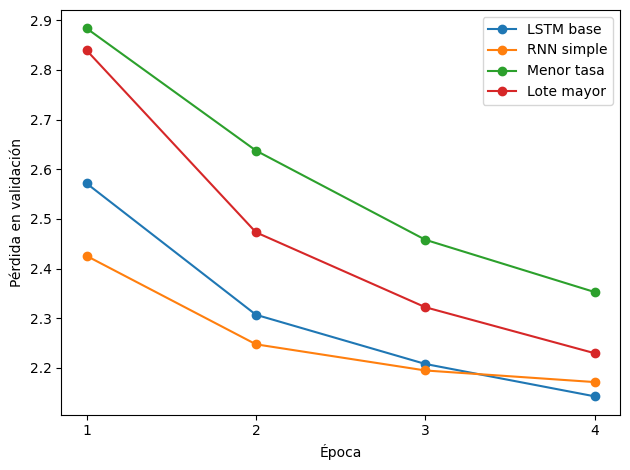

Cambio de F1 de validación frente a LSTM base:


,diferencia
ensayo,
Una época,-0.0768
LSTM base,0.0000
RNN simple,0.0214
Menor tasa,-0.0518
Lote mayor,-0.0252


,accuracy,precisión,recall,F1
RNN simple · prueba,0.36,0.2025,0.1414,0.148


T=0.2: 16 caracteres distintos; comienzo 'on en enter el al el enter en entera en el entende de la manten en entera e'
T=0.5: 20 caracteres distintos; comienzo 'ienter enta mental entende puenero der antente la los rontera en viendia se'
T=1.0: 32 caracteres distintos; comienzo 'enrama lane\ndo, serloviasimoristelque do hos abieno padeon en labereciesiu '
T=1.2: 33 caracteres distintos; comienzo 'róao y loso é no pirce de ncrende iemo sustarardiv, rachos hapal a, alo oso'


**Conclusión recurrente.** RNN simple alcanzó el mayor F1 de validación (0.140). En el tramo final de la novela acertó el 36.0 % de los caracteres. El F1 macro fue 0.148. La exactitud describe predicciones de un paso; los fragmentos anteriores muestran qué ocurre cuando la red se alimenta de sus propios resultados.

In [5]:
for nombre, serie in curvas.items():
    plt.plot(range(1,5), np.array(serie)[:,1], marker="o", label=nombre)
plt.xlabel("Época"); plt.ylabel("Pérdida en validación"); plt.xticks(range(1,5))
plt.legend(); plt.tight_layout(); plt.show()
print("Cambio de F1 de validación frente a LSTM base:")
display((tabla_r.F1 - tabla_r.loc["LSTM base","F1"]).round(4).to_frame("diferencia"))
seleccion_r = crear_recurrente(tipo_r,tasa_r)
seleccion_r.set_weights(pesos_r)
prueba_r = metricas_char(seleccion_r,Xt,yt)
display(pd.DataFrame([prueba_r],index=[eleccion_r+" · prueba"]).round(4))
for t, fragmento in zip(temperaturas,muestras[4]):
    print(f"T={t}: {len(set(fragmento))} caracteres distintos; comienzo {fragmento[:75]!r}")
display(Markdown(f"**Conclusión recurrente.** {eleccion_r} alcanzó el mayor F1 de validación "
                 f"({mejor_f1:.3f}). En el tramo final de la novela acertó el "
                 f"{100*prueba_r['accuracy']:.1f} % de los caracteres. El F1 macro fue "
                 f"{prueba_r['F1']:.3f}. La exactitud describe predicciones de un paso; "
                 "los fragmentos anteriores muestran qué ocurre cuando la red se alimenta de sus propios resultados."))

### Interpretación de la ejecución guardada

**Elección del modelo.** La LSTM y la RNN simple acertaron casi la misma proporción de caracteres en validación (34,28 % y 34,04 %). Al dar igual peso a cada carácter, la RNN simple alcanzó un F1 macro superior (0,140 frente a 0,119). Ese era el criterio fijado para seleccionar el modelo. En prueba alcanzó 36,0 % de aciertos y F1 macro de 0,148. La diferencia entre ambos indicadores invita a revisar por separado los caracteres frecuentes y los raros.

**Efecto de los ajustes.** Entrenar la LSTM cuatro épocas elevó su F1 de 0,042 a 0,119. En cuatro épocas, bajar la tasa a 0,001 dejó el F1 en 0,067. Duplicar el lote a 256 lo dejó en 0,094. Con el mismo número de ejemplos, el lote mayor produjo aproximadamente la mitad de actualizaciones por época. Estos resultados describen una semilla y un presupuesto de entrenamiento concretos.

**Qué se ve al leer.** En la primera época predominaban vocales sueltas. En la segunda empezaron a repetirse «en» y «de». En la tercera y la cuarta aparecieron secuencias más largas. A temperatura 0,2, la cuarta época repitió «entera» y solo utilizó 16 caracteres distintos. A 1,2 utilizó 33 y generó formas difíciles de reconocer, como «ncrende». El modelo captó parte de la ortografía y del ritmo local, pero todavía le cuesta sostener una frase comprensible.
